In [7]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import math
import pickle

# Load model
model = keras.models.load_model('model.keras')

# Import data
with open('data.pkl', 'rb') as inp:
    data = pickle.load(inp)

x_train, y_train, x_test, y_test, x_validate, y_validate = data.values()


# Convert without quantization

In [ ]:
# Create converter
converter = ...

# Create tflite model without quantization
model_no_quant_tflite = ...

# Save model
open("./model_no_quant.tflite", "wb").write(model_no_quant_tflite)

INFO:tensorflow:Assets written to: /tmp/tmpe801rf_c/assets


INFO:tensorflow:Assets written to: /tmp/tmpe801rf_c/assets


Saved artifact at '/tmp/tmpe801rf_c'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140149822317264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822316496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822318608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822318032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822317840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822319376: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1791837142.978292  655886 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791837142.978310  655886 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791837142.978458  655886 reader.cc:83] Reading SavedModel from: /tmp/tmpe801rf_c
I0000 00:00:1791837142.978897  655886 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791837142.978903  655886 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpe801rf_c
I0000 00:00:1791837142.982554  655886 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791837143.009461  655886 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpe801rf_c
I0000 00:00:1791837143.019667  655886 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 41219 microseconds.


3360

# Convert with quantization

In [ ]:
# Set optimization parameters for converter
converter.optimizations = ...

# Create representative dataset which spans full range of input values
def representative_dataset_generator():
    for i in range(500):
        yield([x_train[i].reshape(1,1).astype('float32')])

# Enfore integer only quantization
converter.target_spec.supported_ops = ...

# Provide representative dataset to ensure we quantize correctly
converter.representative_dataset = ...

# Create quantized model
model_quant_tflite = ...

# Save model to disk
open("./model_quant.tflite", "wb").write(model_quant_tflite)

INFO:tensorflow:Assets written to: /tmp/tmp4ghsxkj_/assets


INFO:tensorflow:Assets written to: /tmp/tmp4ghsxkj_/assets


Saved artifact at '/tmp/tmp4ghsxkj_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 1), dtype=tf.float32, name='input_layer_4')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  140149822317264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822316496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822318608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822318032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822317840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140149822319376: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/wuster/projects/python/TinyML_Pub/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1791838086.763370  655886 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1791838086.763406  655886 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1791838086.763599  655886 reader.cc:83] Reading SavedModel from: /tmp/tmp4ghsxkj_
I0000 00:00:1791838086.764092  655886 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1791838086.764100  655886 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp4ghsxkj_
I0000 00:00:1791838086.768041  655886 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1791838086.794805  655886 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp4ghsxkj_
I0000 00:00:1791838086.803348  655886 loader.cc:471] SavedMo

3952

# Show model accuracy

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


/home/wuster/projects/python/TinyML_Pub/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


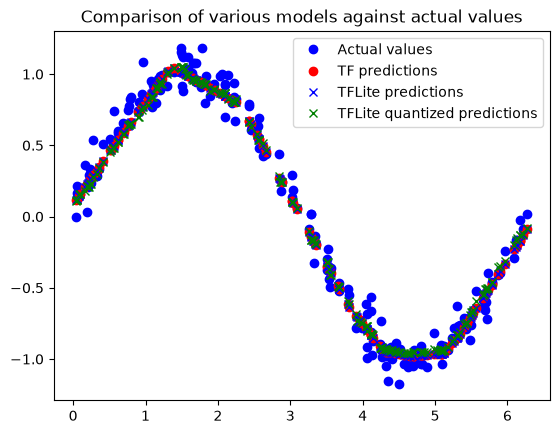

In [ ]:
def predict_tflite(tflite_model, x_test):
    # Prepare the test data
    x_test_ = x_test.copy()
    x_test_ = x_test_.reshape((x_test.size, 1))
    x_test_ = x_test_.astype(np.float32)

    # Init the TFLite Interpreter
    interpreter = tf.lite.Interpreter(model_content=tflite_model, experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_REF)

    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    # If required, quantize the input layer (from float to integer)
    input_scale, input_zero_point = input_details["quantization"]
    if (input_scale, input_zero_point) != (0.0, 0):
        x_test_ = x_test_ / input_scale + input_zero_point
        x_test_ = x_test_.astype(input_details["dtype"])
    
    # Invoke the interpreter
    y_pred = []
    for i in range(len(x_test_)):
        interpreter.set_tensor(input_details["index"], [x_test_[i]])
        interpreter.invoke()
        y_pred.append(interpreter.get_tensor(output_details["index"])[0])
    
    # If required, dequantize the output layer (from integer to float)
    output_scale, output_zero_point = output_details["quantization"]
    if (output_scale, output_zero_point) != (0.0, 0):
        y_pred = np.array(y_pred, dtype=np.float32) 
        y_pred = (y_pred - output_zero_point) * output_scale
    
    return y_pred


# Calculate predictions
y_test_pred_tf = ...
y_test_pred_no_quant_tflite = ...
y_test_pred_quant_tflite = ...

# See how prediction lines up with data
plt.clf()
plt.title('Comparison of various models against actual values')
plt.plot(..., label='Actual values')
plt.plot(..., label='TF predictions')
plt.plot(..., label='TFLite predictions')
plt.plot(..., label='TFLite quantized predictions')
...
plt.show()

# Convert to C file

In [27]:
# Install xxd if it is not available
! apt-get update && apt-get -qq install xxd

MODEL_QUANT_TFLITE = './model_quant.tflite'
MODEL_TFLITE_MICRO = './sine_model_quantized.cc'

# Save the file as a C source file
! xxd -i {MODEL_QUANT_TFLITE} > {MODEL_TFLITE_MICRO}

# Update variable names using sed
REPLACE_TEXT = MODEL_QUANT_TFLITE.replace('/', '_').replace('.', '_')
! sed -i 's/'{REPLACE_TEXT}'/g_model/g' {MODEL_TFLITE_MICRO}

# Print the source file
! cat {MODEL_TFLITE_MICRO}

zsh:1: command not found: apt-get
unsigned char g_model[] = {
  0x20, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x00, 0x00, 0x00, 0x00,
  0x14, 0x00, 0x20, 0x00, 0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00,
  0x0c, 0x00, 0x00, 0x00, 0x08, 0x00, 0x04, 0x00, 0x14, 0x00, 0x00, 0x00,
  0x1c, 0x00, 0x00, 0x00, 0x98, 0x00, 0x00, 0x00, 0xf0, 0x00, 0x00, 0x00,
  0xc4, 0x03, 0x00, 0x00, 0xd4, 0x03, 0x00, 0x00, 0xf8, 0x0e, 0x00, 0x00,
  0x03, 0x00, 0x00, 0x00, 0x01, 0x00, 0x00, 0x00, 0x10, 0x00, 0x00, 0x00,
  0x00, 0x00, 0x0a, 0x00, 0x10, 0x00, 0x0c, 0x00, 0x08, 0x00, 0x04, 0x00,
  0x0a, 0x00, 0x00, 0x00, 0x0c, 0x00, 0x00, 0x00, 0x1c, 0x00, 0x00, 0x00,
  0x3c, 0x00, 0x00, 0x00, 0x0f, 0x00, 0x00, 0x00, 0x73, 0x65, 0x72, 0x76,
  0x69, 0x6e, 0x67, 0x5f, 0x64, 0x65, 0x66, 0x61, 0x75, 0x6c, 0x74, 0x00,
  0x01, 0x00, 0x00, 0x00, 0x04, 0x00, 0x00, 0x00, 0x90, 0xff, 0xff, 0xff,
  0x0b, 0x00, 0x00, 0x00, 0x04, 0x00, 0x00, 0x00, 0x08, 0x00, 0x00, 0x00,
  0x6f, 0x75, 0x74, 0x70, 0x75, 0x74, 0x5f, 0x30, 